# Анализ воронки регистрации мобильного приложения

**Уровень:** Intern  
**Направление:** Product Analyst  
**Задача:** понять, сколько пользователей проходит основные шаги знакомства с приложением и на каком шаге больше всего потерь.

Данные в `data/events_demo.csv` **синтетические**: они сгенерированы для учебного задания. В ноутбуке используются базовые операции Pandas и простые проценты. A/B-тесты, когортный анализ и сложная статистика здесь не нужны.

## 1. Загрузка данных

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "events_demo.csv"
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, parse_dates=["event_time"])
df.head()

,user_id,event_name,event_time,device,source
0,U00001,visit_landing,2025-09-27 07:29:00,Android,Реклама
1,U00001,sign_up,2025-09-27 08:29:00,Android,Реклама
2,U00001,complete_profile,2025-09-27 11:11:00,Android,Реклама
3,U00001,first_key_action,2025-09-27 14:03:00,Android,Реклама
4,U00002,visit_landing,2025-09-23 07:04:00,iOS,Соцсети


## 2. Проверка таблицы

In [2]:
print("Строк и столбцов:", df.shape)
print("Уникальных пользователей:", df["user_id"].nunique())
print("\nПропуски:")
print(df.isna().sum())
print("\nДубликаты:", df.duplicated().sum())
print("\nСобытия:")
print(df["event_name"].value_counts())

Строк и столбцов: (4916, 5)
Уникальных пользователей: 2500

Пропуски:
user_id       0
event_name    0
event_time    0
device        0
source        0
dtype: int64

Дубликаты: 0

События:
event_name
visit_landing       2500
sign_up             1137
complete_profile     789
first_key_action     490
Name: count, dtype: int64


## 3. Строим простую воронку

Шаги: посещение страницы → регистрация → заполнение профиля → первое целевое действие. Для каждого шага считаем уникальных пользователей.

In [3]:
steps = ["visit_landing", "sign_up", "complete_profile", "first_key_action"]
step_names = ["Посетили страницу", "Зарегистрировались", "Заполнили профиль", "Сделали первое действие"]

users_by_step = (df.groupby("event_name")["user_id"].nunique()
                   .reindex(steps, fill_value=0))

funnel = pd.DataFrame({"step": step_names, "users": users_by_step.values})
funnel["conversion_from_previous"] = funnel["users"] / funnel["users"].shift(1)
funnel.loc[0, "conversion_from_previous"] = 1
funnel["conversion_from_start"] = funnel["users"] / funnel.loc[0, "users"]
funnel

,step,users,conversion_from_previous,conversion_from_start
0,Посетили страницу,2500,1.000000,1.0000
1,Зарегистрировались,1137,0.454800,0.4548
2,Заполнили профиль,789,0.693931,0.3156
3,Сделали первое действие,490,0.621039,0.1960


## 4. Считаем потери между шагами

In [4]:
funnel["lost_users"] = funnel["users"].shift(1) - funnel["users"]
funnel.loc[0, "lost_users"] = 0
funnel["drop_off_rate"] = 1 - funnel["conversion_from_previous"]
funnel

,step,users,conversion_from_previous,conversion_from_start,lost_users,drop_off_rate
0,Посетили страницу,2500,1.000000,1.0000,0.0,0.000000
1,Зарегистрировались,1137,0.454800,0.4548,1363.0,0.545200
2,Заполнили профиль,789,0.693931,0.3156,348.0,0.306069
3,Сделали первое действие,490,0.621039,0.1960,299.0,0.378961


## 5. Визуализация воронки

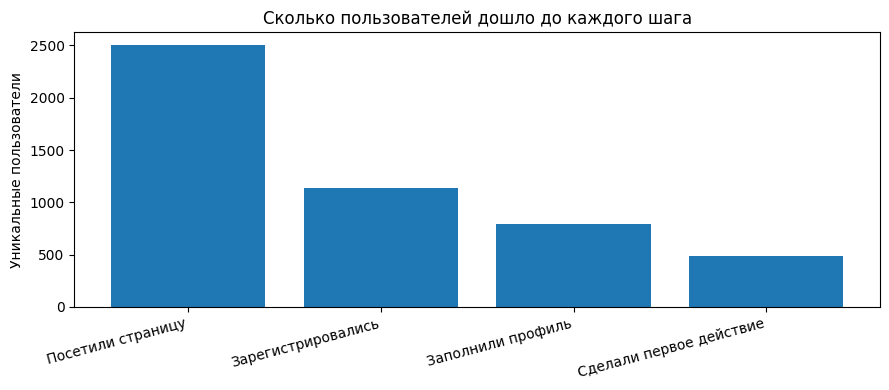

In [5]:
plt.figure(figsize=(9, 4))
plt.bar(funnel["step"], funnel["users"])
plt.title("Сколько пользователей дошло до каждого шага")
plt.ylabel("Уникальные пользователи")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(FIGURES / "onboarding_funnel.png", dpi=150)
plt.show()

## 6. Сравнение источников трафика

Посмотрим, какая доля пользователей из каждого источника дошла до первого целевого действия. Это простое сравнение долей на учебных данных.

In [6]:
user_level = (df.pivot_table(index=["user_id", "device", "source"],
                            columns="event_name", values="event_time",
                            aggfunc="min", observed=False)
                .reset_index())
user_level["completed_first_action"] = user_level["first_key_action"].notna()
source_conversion = (user_level.groupby("source", as_index=False)
                     .agg(users=("user_id", "nunique"),
                          users_with_action=("completed_first_action", "sum")))
source_conversion["conversion"] = source_conversion["users_with_action"] / source_conversion["users"]
source_conversion.sort_values("conversion", ascending=False)

,source,users,users_with_action,conversion
1,Прямой переход,363,82,0.225895
3,Соцсети,588,119,0.202381
2,Реклама,681,128,0.187959
0,Поиск,868,161,0.185484


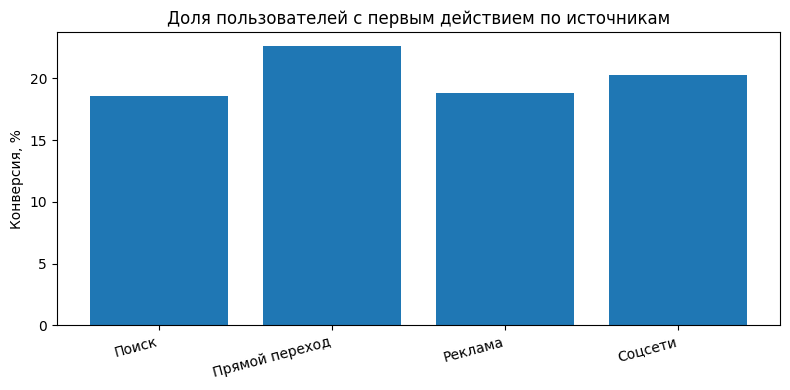

In [7]:
plt.figure(figsize=(8, 4))
plt.bar(source_conversion["source"], source_conversion["conversion"] * 100)
plt.title("Доля пользователей с первым действием по источникам")
plt.ylabel("Конверсия, %")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(FIGURES / "conversion_by_source.png", dpi=150)
plt.show()

## 7. Простые выводы

Результаты показывают, на каких этапах воронки теряется больше пользователей. Это отправная точка для проверки интерфейса и качества трафика, но не доказательство причины оттока.

In [8]:
largest_loss = funnel.iloc[1:].sort_values("lost_users", ascending=False).iloc[0]
final_conversion = funnel.loc[funnel.index[-1], "conversion_from_start"]
print(f"Самая большая абсолютная потеря произошла на шаге: {largest_loss['step']}.")
print(f"До первого целевого действия дошли {final_conversion:.1%} пользователей от начального шага.")
print("\nВажно: данные сгенерированы. По ним нельзя делать выводы о реальном приложении.")

Самая большая абсолютная потеря произошла на шаге: Зарегистрировались.
До первого целевого действия дошли 19.6% пользователей от начального шага.

Важно: данные сгенерированы. По ним нельзя делать выводы о реальном приложении.


## 8. Что можно улучшить дальше

- Сравнить воронку отдельно для Android, iOS и Web.
- Добавить разрез по датам.
- Проверить, сколько времени проходит между регистрацией и первым действием.
- Визуализировать воронку в DataLens или Power BI.

На этом уровне достаточно корректно посчитать пользователей на каждом шаге, конверсии и потери.